In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))
from qsegment import metrics as mt, scenario as sc

R = {name: json.loads((ROOT / "results" / f"{name}.json").read_text())
     for name in ("01_verify", "02_baselines", "02b_gurobi", "03_qaoa_repeats", "04_noisy_sim", "05_backend_choice", "06_hardware_probe", "07_hardware_final")}
Q3, H4, H5, H6, H7 = R["03_qaoa_repeats"], R["04_noisy_sim"], R["05_backend_choice"], R["06_hardware_probe"], R["07_hardware_final"]

plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False,
                     "figure.facecolor": "white", "axes.facecolor": "white", "figure.dpi": 110})
BLUE, GREEN, RED, PURPLE, ORANGE, GRAY = "#1f77b4", "#2ca02c", "#d62728", "#9467bd", "#f28e2b", "#6b7280"
LEGEND = dict(frameon=True, facecolor="white", edgecolor="#d1d5db", framealpha=0.95, fontsize=9)
RANDOM = 100 / 128
se = lambda x: float(np.std(x, ddof=1) / np.sqrt(len(x)))
JOBS = {(j["variant"], j["p"]): j for j in H7["jobs"]}
hw = lambda job, mode, key: np.array([r[mode][key] for r in job["results"]])

## The best split

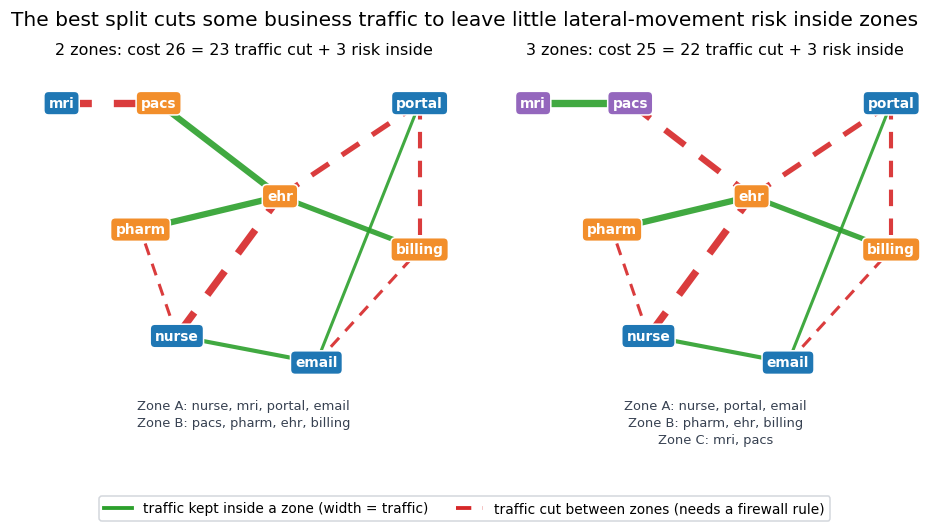

In [2]:
from matplotlib.lines import Line2D

POS = {"ehr": (0, 0), "pacs": (-2, 1.4), "mri": (-3.6, 1.4), "pharm": (-2.3, -0.5), "nurse": (-1.7, -2.1),
       "email": (0.6, -2.5), "billing": (2.3, -0.8), "portal": (2.3, 1.4)}
ZONE_COLORS = [BLUE, ORANGE, PURPLE]
fig, axes = plt.subplots(1, 2, figsize=(10.8, 4.8))
for ax, K in zip(axes, (2, 3)):
    costs = sc.cost_table(K)
    best = min(costs)
    z = sc.decode(costs.index(best), K)
    traffic_cut = sum(sc.traffic(i, j) for i, j in sc.PAIRS if z[i] != z[j])
    risk_inside = sum(sc.risk(i, j) for i, j in sc.PAIRS if z[i] == z[j])
    for i, j in sc.PAIRS:
        t = sc.traffic(i, j)
        if t:
            (x1, y1), (x2, y2) = POS[sc.SYSTEMS[i]], POS[sc.SYSTEMS[j]]
            kept = z[i] == z[j]
            ax.plot([x1, x2], [y1, y2], color=GREEN if kept else RED, ls="-" if kept else (0, (4, 3)), lw=0.7 * t + 0.6, alpha=0.9, zorder=1)
    for i, name in enumerate(sc.SYSTEMS):
        ax.text(*POS[name], name, ha="center", va="center", color="white", fontsize=9, fontweight="bold", zorder=3,
                bbox=dict(boxstyle="round,pad=0.35", fc=ZONE_COLORS[z[i]], ec="white"))
    ax.set_xlim(-4.3, 3.1)
    ax.set_ylim(-3.0, 2.0)
    ax.axis("off")
    zones = "\n".join(f"Zone {chr(65 + k)}: {', '.join(n for n, zz in zip(sc.SYSTEMS, z) if zz == k)}" for k in range(K))
    ax.set_title(f"{K} zones: cost {best:.0f} = {traffic_cut} traffic cut + {risk_inside} risk inside", fontsize=10.5)
    ax.text(0.5, -0.01, zones, transform=ax.transAxes, ha="center", va="top", fontsize=8.5, color="#374151", linespacing=1.4)
fig.suptitle("The best split cuts some business traffic to leave little lateral-movement risk inside zones")
fig.legend(handles=[Line2D([0], [0], color=GREEN, lw=2.5, label="traffic kept inside a zone (width = traffic)"),
                    Line2D([0], [0], color=RED, lw=2.5, ls=(0, (4, 3)), label="traffic cut between zones (needs a firewall rule)")],
           loc="lower center", ncol=2, bbox_to_anchor=(0.5, 0.0), **LEGEND)
fig.subplots_adjust(bottom=0.25, top=0.88, wspace=0.05)
plt.show()

## The circuit

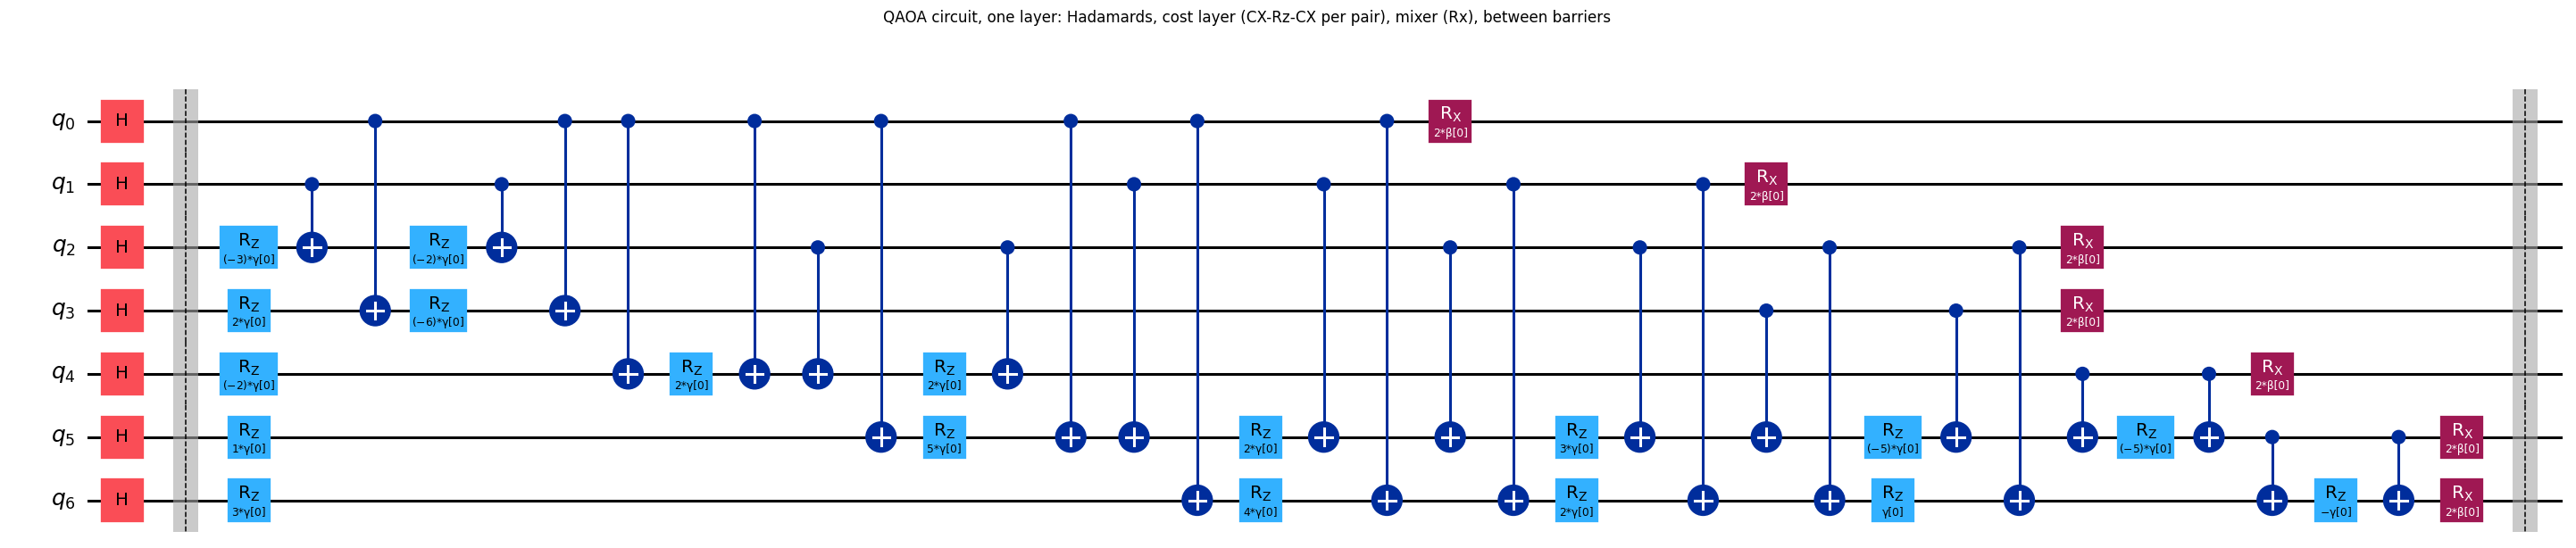

In [3]:
from qiskit import QuantumCircuit, transpile
from qiskit.circuit.library import QAOAAnsatz

from qsegment import formulation as fm

H, _ = fm.ising_2zone()
init = QuantumCircuit(H.num_qubits)
init.h(range(H.num_qubits))
init.barrier()
ansatz = QAOAAnsatz(cost_operator=H, reps=1, initial_state=init)
ansatz.insert_barriers = True
logical = transpile(ansatz, basis_gates=["h", "cx", "rz", "rx"], optimization_level=0)
fig = logical.draw("mpl", fold=40)
fig.suptitle("QAOA circuit, one layer: Hadamards, cost layer (CX-Rz-CX per pair), mixer (Rx), between barriers", fontsize=11)
fig

## QAOA against random guessing

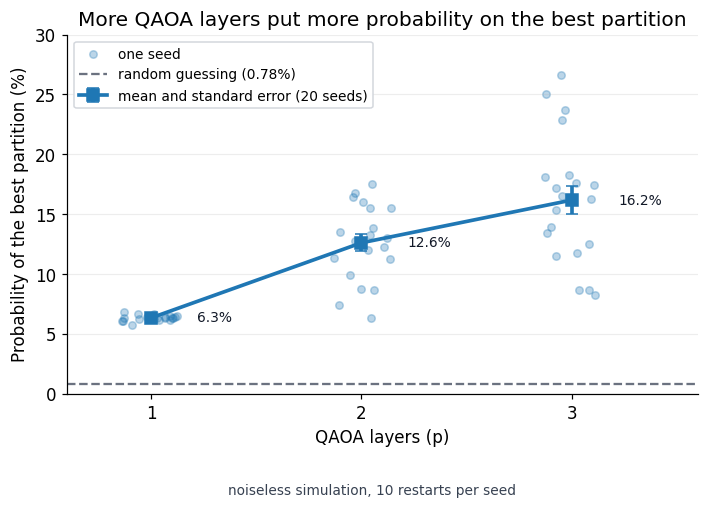

In [4]:
ps = [1, 2, 3]
rng = np.random.default_rng(0)
fig, ax = plt.subplots(figsize=(7.4, 4.8))
means, errs = [], []
for p in ps:
    vals = [100 * r["ideal"]["p_best"] for r in Q3["runs"][str(p)]]
    means.append(np.mean(vals))
    errs.append(se(vals))
    ax.scatter(p + rng.uniform(-0.14, 0.14, len(vals)), vals, s=24, color=BLUE, alpha=0.3, marker="o", label="one seed" if p == 1 else None)
ax.errorbar(ps, means, yerr=errs, color=BLUE, marker="s", ms=8, lw=2.4, capsize=4, label="mean and standard error (20 seeds)")
ax.axhline(RANDOM, color=GRAY, ls="--", lw=1.5, label="random guessing (0.78%)")
for p, m in zip(ps, means):
    ax.text(p + 0.22, m, f"{m:.1f}%", va="center", fontsize=9, color="#111827")
ax.set(xticks=ps, xlabel="QAOA layers (p)", ylabel="Probability of the best partition (%)", ylim=(0, 30), xlim=(0.6, 3.6))
ax.yaxis.grid(True, alpha=0.22)
ax.legend(loc="upper left", **LEGEND)
ax.set_title("More QAOA layers put more probability on the best partition")
fig.text(0.5, 0.01, "noiseless simulation, 10 restarts per seed", ha="center", fontsize=9, color="#374151")
fig.subplots_adjust(bottom=0.2)
plt.show()

## Time against classical search

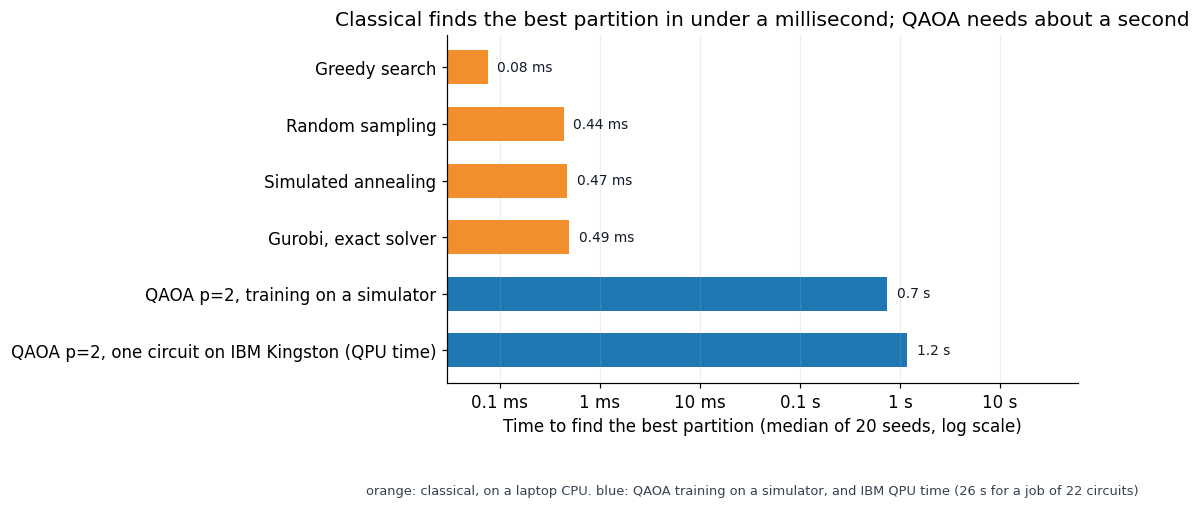

In [5]:
from matplotlib.ticker import FixedLocator, FuncFormatter, NullLocator

base = R["02_baselines"]["summary"]
classical = [("Greedy search", base["greedy"]["seconds_to_first_hit"]["median"]),
             ("Simulated annealing", base["annealing"]["seconds_to_first_hit"]["median"]),
             ("Random sampling", base["random"]["seconds_to_first_hit"]["median"]),
             ("Gurobi, exact solver", R["02b_gurobi"]["summary"]["solve_seconds"]["median"])]
job = JOBS[("main", 2)]
qaoa = [("QAOA p=2, training on a simulator", Q3["summary"]["2"]["tuning_seconds"]["median"]),
        ("QAOA p=2, one circuit on IBM Kingston (QPU time)", job["usage_seconds"] / (job["sets"] + 2))]
rows = sorted(classical, key=lambda r: r[1]) + qaoa
colors = [ORANGE] * len(classical) + [BLUE] * len(qaoa)
fmt = lambda s: f"{s * 1e3:.2f} ms" if s < 0.1 else f"{s:.1f} s"
fig, ax = plt.subplots(figsize=(7.4, 4.8))
ax.barh([r[0] for r in rows], [r[1] for r in rows], color=colors, height=0.6)
ax.set_xscale("log")
ax.set_xlim(3e-5, 60)
ax.xaxis.set_major_locator(FixedLocator([1e-4, 1e-3, 1e-2, 1e-1, 1, 10]))
ax.set_xticklabels(["0.1 ms", "1 ms", "10 ms", "0.1 s", "1 s", "10 s"])
ax.xaxis.set_minor_locator(NullLocator())
for y, (_, v) in enumerate(rows):
    ax.text(v * 1.25, y, fmt(v), va="center", fontsize=9, color="#111827")
ax.set_xlabel("Time to find the best partition (median of 20 seeds, log scale)")
ax.xaxis.grid(True, alpha=0.22)
ax.invert_yaxis()
ax.set_title("Classical finds the best partition in under a millisecond; QAOA needs about a second")
fig.text(0.5, 0.01, "orange: classical, on a laptop CPU. blue: QAOA training on a simulator, and IBM QPU time (26 s for a job of 22 circuits)", ha="center", fontsize=8.5, color="#374151")
fig.subplots_adjust(bottom=0.22)
plt.show()

## Real hardware

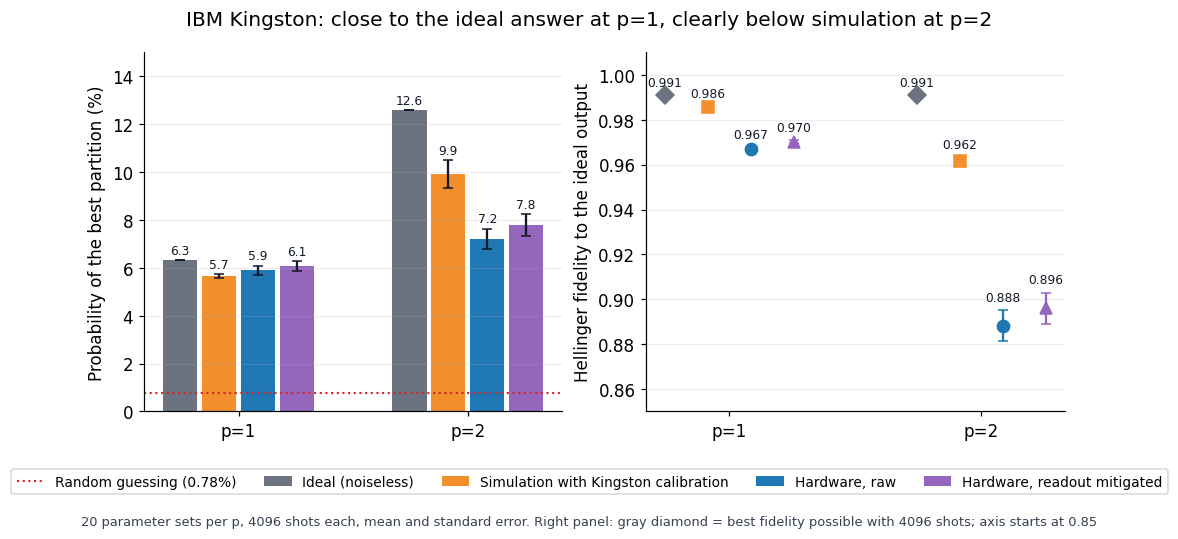

In [6]:
ps = (1, 2)
modes = [("Ideal (noiseless)", None, GRAY, "D"), ("Simulation with Kingston calibration", "same_day_simulation", ORANGE, "s"),
         ("Hardware, raw", "hardware_raw", BLUE, "o"), ("Hardware, readout mitigated", "hardware_mitigated", PURPLE, "^")]
floor = np.mean([r["summary"]["shot_floor"]["hellinger"]["mean"] for r in H4["results"]])
fig, axes = plt.subplots(1, 2, figsize=(10.8, 4.8))
for k, (name, mode, color, marker) in enumerate(modes):
    off = (k - 1.5) * 0.17
    pb, hl = [], []
    for p in ps:
        job = JOBS[("main", p)]
        if mode is None:
            pb.append((100 * np.mean([r["ideal_p_best"] for r in job["results"]]), 0))
            hl.append((floor, 0))
        else:
            v, h = 100 * hw(job, mode, "p_best"), hw(job, mode, "hellinger")
            pb.append((v.mean(), se(v)))
            hl.append((h.mean(), se(h)))
    x = [p + off for p in ps]
    axes[0].bar(x, [a for a, _ in pb], width=0.15, color=color, label=name, yerr=[b for _, b in pb], capsize=3, ecolor="#111827")
    for xi, (a, e) in zip(x, pb):
        axes[0].text(xi, a + e + 0.25, f"{a:.1f}", ha="center", fontsize=8, color="#111827")
    axes[1].errorbar(x, [a for a, _ in hl], yerr=[b for _, b in hl], fmt=marker, color=color, ms=8, capsize=3, label="Shot-noise ceiling (4096 shots)" if mode is None else name)
    for xi, (a, e) in zip(x, hl):
        axes[1].text(xi, a + e + 0.004, f"{a:.3f}", ha="center", fontsize=8, color="#111827")
axes[0].axhline(RANDOM, color=RED, ls=":", lw=1.4, label="Random guessing (0.78%)")
axes[0].set(xticks=ps, xticklabels=["p=1", "p=2"], ylabel="Probability of the best partition (%)", ylim=(0, 15))
axes[1].set(xticks=ps, xticklabels=["p=1", "p=2"], ylabel="Hellinger fidelity to the ideal output", ylim=(0.85, 1.01))
axes[0].yaxis.grid(True, alpha=0.22)
axes[1].yaxis.grid(True, alpha=0.22)
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=5, bbox_to_anchor=(0.5, 0.05), **LEGEND)
fig.suptitle("IBM Kingston: close to the ideal answer at p=1, clearly below simulation at p=2")
fig.text(0.5, 0.005, "20 parameter sets per p, 4096 shots each, mean and standard error. Right panel: gray diamond = best fidelity possible with 4096 shots; axis starts at 0.85", ha="center", fontsize=8.5, color="#374151")
fig.subplots_adjust(bottom=0.22, top=0.9)
plt.show()

## Mitigation on hardware

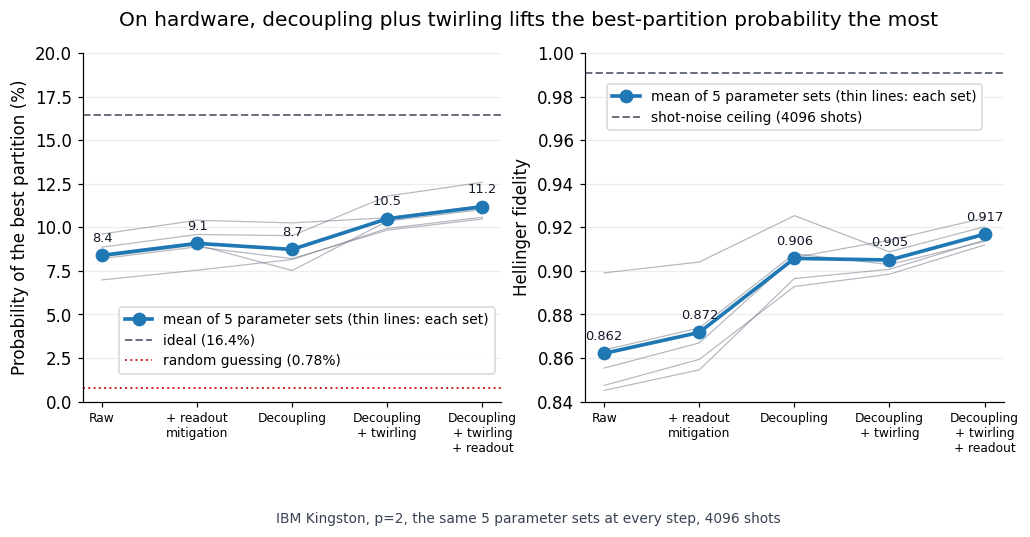

In [7]:
main, dd, ddt = JOBS[("main", 2)], JOBS[("dd", 2)], JOBS[("dd_twirl", 2)]
assert dd["seeds"] == ddt["seeds"]
idx = [main["seeds"].index(s) for s in dd["seeds"]]
steps = [("Raw", main, "hardware_raw", True), ("+ readout\nmitigation", main, "hardware_mitigated", True),
         ("Decoupling", dd, "hardware_raw", False), ("Decoupling\n+ twirling", ddt, "hardware_raw", False),
         ("Decoupling\n+ twirling\n+ readout", ddt, "hardware_mitigated", False)]
ideal = 100 * np.array([main["results"][i]["ideal_p_best"] for i in idx]).mean()
floor = np.mean([r["summary"]["shot_floor"]["hellinger"]["mean"] for r in H4["results"]])
fig, axes = plt.subplots(1, 2, figsize=(10.8, 4.8))
for ax, key, scale, label in ((axes[0], "p_best", 100, "Probability of the best partition (%)"), (axes[1], "hellinger", 1, "Hellinger fidelity")):
    vals = np.array([(hw(job, mode, key)[idx] if use else hw(job, mode, key)) * scale for _, job, mode, use in steps])
    ax.plot(range(5), vals, color=GRAY, lw=0.8, alpha=0.5)
    ax.plot(range(5), vals.mean(axis=1), color=BLUE, marker="o", ms=8, lw=2.4, label="mean of 5 parameter sets (thin lines: each set)")
    for x, m in enumerate(vals.mean(axis=1)):
        ax.annotate(f"{m:.1f}" if key == "p_best" else f"{m:.3f}", (x, m), textcoords="offset points", xytext=(0, 9), ha="center", fontsize=8.5, color="#111827")
    ax.set(xticks=range(5), xticklabels=[s[0] for s in steps], ylabel=label)
    ax.tick_params(axis="x", labelsize=8)
    ax.yaxis.grid(True, alpha=0.22)
axes[0].axhline(ideal, color=GRAY, ls="--", lw=1.3, label=f"ideal ({ideal:.1f}%)")
axes[0].axhline(RANDOM, color=RED, ls=":", lw=1.3, label="random guessing (0.78%)")
axes[0].set_ylim(0, 20)
axes[1].axhline(floor, color=GRAY, ls="--", lw=1.3, label="shot-noise ceiling (4096 shots)")
axes[1].set_ylim(0.84, 1.0)
axes[0].legend(loc="lower right", bbox_to_anchor=(1.0, 0.06), **LEGEND)
axes[1].legend(loc="upper center", bbox_to_anchor=(0.5, 0.93), **LEGEND)
fig.suptitle("On hardware, decoupling plus twirling lifts the best-partition probability the most")
fig.text(0.5, 0.01, "IBM Kingston, p=2, the same 5 parameter sets at every step, 4096 shots", ha="center", fontsize=9, color="#374151")
fig.subplots_adjust(bottom=0.24, top=0.9)
plt.show()

## Results at a glance

In [8]:
q3 = Q3["summary"]
rows = [("Random guessing", f"{RANDOM:.2f}", "", "")]
for p in (1, 2, 3):
    v = [100 * r["ideal"]["p_best"] for r in Q3["runs"][str(p)]]
    rows.append((f"QAOA, noiseless, p={p} (20 sets)", f"{np.mean(v):.2f} ± {se(v):.2f}", "reference", ""))
for p in (1, 2):
    job = JOBS[("main", p)]
    ideal = 100 * np.mean([r["ideal_p_best"] for r in job["results"]])
    for label, mode in (("Simulation, Kingston calibration", "same_day_simulation"), ("Hardware, raw", "hardware_raw"), ("Hardware, readout mitigated", "hardware_mitigated")):
        v, h = 100 * hw(job, mode, "p_best"), hw(job, mode, "hellinger")
        rows.append((f"{label}, p={p} (20 sets)", f"{v.mean():.2f} ± {se(v):.2f}", f"{v.mean() / ideal:.0%}", f"{h.mean():.3f}"))
main, ddt = JOBS[("main", 2)], JOBS[("dd_twirl", 2)]
idx = [main["seeds"].index(s) for s in ddt["seeds"]]
ideal5 = 100 * np.mean([main["results"][i]["ideal_p_best"] for i in idx])
v, h = 100 * hw(ddt, "hardware_mitigated", "p_best"), hw(ddt, "hardware_mitigated", "hellinger")
rows.append(("Hardware, decoupling + twirling + readout mitigated, p=2 (5 sets)", f"{v.mean():.2f} ± {se(v):.2f}", f"{v.mean() / ideal5:.0%}", f"{h.mean():.3f}"))
table = pd.DataFrame(rows, columns=["Setting", "Best-partition probability (%, mean ± se)", "Share of ideal", "Hellinger fidelity"])
table.style.hide(axis="index").set_properties(**{"text-align": "left"})

Setting,"Best-partition probability (%, mean ± se)",Share of ideal,Hellinger fidelity
Random guessing,0.78,,
"QAOA, noiseless, p=1 (20 sets)",6.34 ± 0.05,reference,
"QAOA, noiseless, p=2 (20 sets)",12.61 ± 0.72,reference,
"QAOA, noiseless, p=3 (20 sets)",16.18 ± 1.20,reference,
"Simulation, Kingston calibration, p=1 (20 sets)",5.66 ± 0.08,89%,0.986
"Hardware, raw, p=1 (20 sets)",5.90 ± 0.19,93%,0.967
"Hardware, readout mitigated, p=1 (20 sets)",6.09 ± 0.20,96%,0.970
"Simulation, Kingston calibration, p=2 (20 sets)",9.93 ± 0.59,79%,0.962
"Hardware, raw, p=2 (20 sets)",7.21 ± 0.43,57%,0.888
"Hardware, readout mitigated, p=2 (20 sets)",7.79 ± 0.47,62%,0.896


## 3 zones

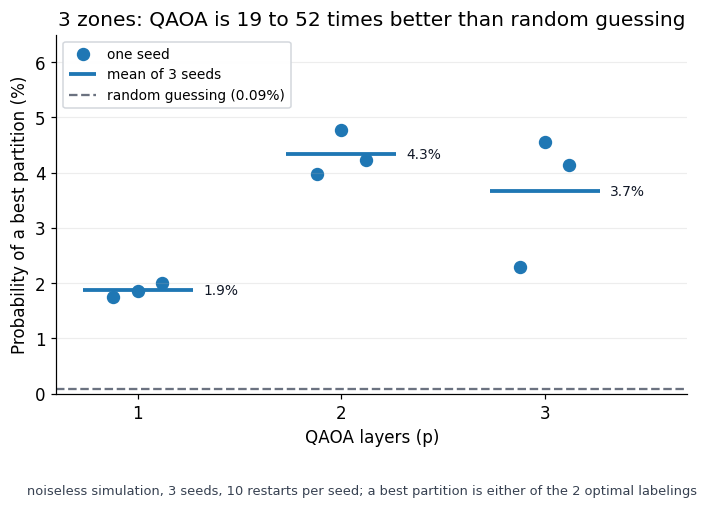

In [9]:
Q10 = json.loads((ROOT / "results" / "10_qaoa_3zone.json").read_text())
runs3 = Q10["runs"]
random3 = 100 * 2 / 3 ** 7
vals_all = [100 * r["ideal"]["p_best"] for r in runs3]
fig, ax = plt.subplots(figsize=(7.4, 4.8))
for p in (1, 2, 3):
    vals = [100 * r["ideal"]["p_best"] for r in runs3 if r["p"] == p]
    ax.scatter(p + np.array([-0.12, 0, 0.12]), vals, s=60, color=BLUE, marker="o", label="one seed" if p == 1 else None)
    ax.hlines(np.mean(vals), p - 0.27, p + 0.27, color=BLUE, lw=2.5, label="mean of 3 seeds" if p == 1 else None)
    ax.text(p + 0.32, np.mean(vals), f"{np.mean(vals):.1f}%", va="center", fontsize=9, color="#111827")
ax.axhline(random3, color=GRAY, ls="--", lw=1.5, label=f"random guessing ({random3:.2f}%)")
ax.set(xticks=[1, 2, 3], xlabel="QAOA layers (p)", ylabel="Probability of a best partition (%)", ylim=(0, 6.5), xlim=(0.6, 3.7))
ax.yaxis.grid(True, alpha=0.22)
ax.legend(loc="upper left", **LEGEND)
ax.set_title(f"3 zones: QAOA is {min(vals_all) / random3:.0f} to {max(vals_all) / random3:.0f} times better than random guessing")
fig.text(0.5, 0.01, "noiseless simulation, 3 seeds, 10 restarts per seed; a best partition is either of the 2 optimal labelings", ha="center", fontsize=8.5, color="#374151")
fig.subplots_adjust(bottom=0.2)
plt.show()

## 3 zones on real hardware

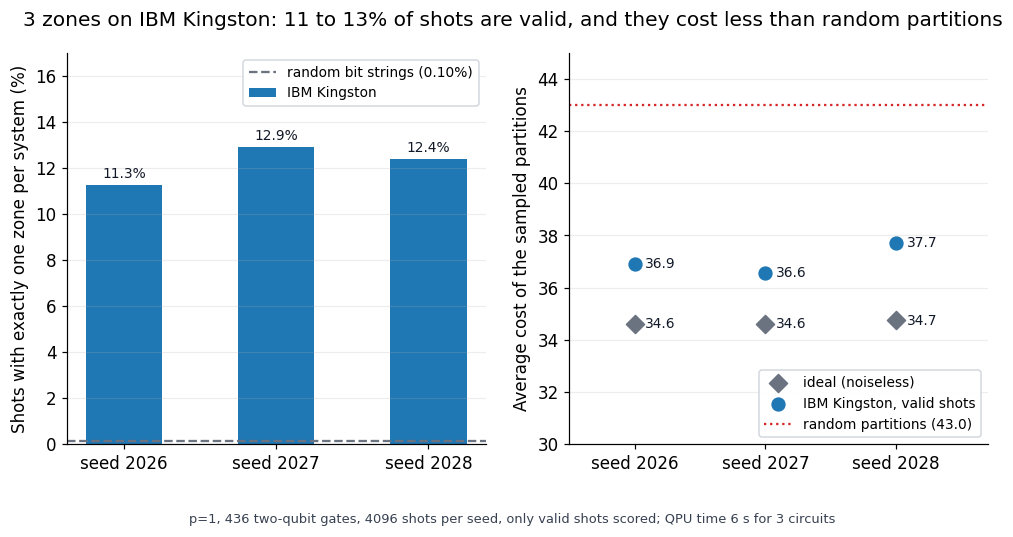

In [10]:
H12 = json.loads((ROOT / "results" / "12_hardware_3zone.json").read_text())
rows3 = H12["results"]
assert all(r["avg_cost_of_valid_shots"] < 43.0 for r in rows3)
x = np.arange(len(rows3))
labels = [f"seed {r['seed']}" for r in rows3]
valid = [100 * r["valid_share"] for r in rows3]
fig, axes = plt.subplots(1, 2, figsize=(10.8, 4.8))
axes[0].bar(x, valid, color=BLUE, width=0.5, label="IBM Kingston")
for xi, v in zip(x, valid):
    axes[0].text(xi, v + 0.3, f"{v:.1f}%", ha="center", fontsize=9, color="#111827")
axes[0].axhline(100 * H12["random_bitstring_valid_share"], color=GRAY, ls="--", lw=1.5, label=f"random bit strings ({100 * H12['random_bitstring_valid_share']:.2f}%)")
axes[0].set(xticks=x, xticklabels=labels, ylabel="Shots with exactly one zone per system (%)", ylim=(0, 17))
axes[0].legend(loc="upper right", **LEGEND)
axes[1].scatter(x, [r["ideal_avg_cost"] for r in rows3], color=GRAY, marker="D", s=70, label="ideal (noiseless)")
axes[1].scatter(x, [r["avg_cost_of_valid_shots"] for r in rows3], color=BLUE, marker="o", s=70, label="IBM Kingston, valid shots")
for xi, r in zip(x, rows3):
    axes[1].text(xi + 0.08, r["avg_cost_of_valid_shots"], f"{r['avg_cost_of_valid_shots']:.1f}", va="center", fontsize=9, color="#111827")
    axes[1].text(xi + 0.08, r["ideal_avg_cost"], f"{r['ideal_avg_cost']:.1f}", va="center", fontsize=9, color="#111827")
axes[1].axhline(43.0, color=RED, ls=":", lw=1.5, label="random partitions (43.0)")
axes[1].set(xticks=x, xticklabels=labels, ylabel="Average cost of the sampled partitions", ylim=(30, 45), xlim=(-0.5, 2.7))
axes[1].legend(loc="lower right", **LEGEND)
for ax in axes:
    ax.yaxis.grid(True, alpha=0.22)
fig.suptitle(f"3 zones on IBM Kingston: {min(valid):.0f} to {max(valid):.0f}% of shots are valid, and they cost less than random partitions")
fig.text(0.5, 0.01, f"p=1, {H12['chosen_transpile']['two_qubit_gates']} two-qubit gates, 4096 shots per seed, only valid shots scored; QPU time {H12['usage_seconds']} s for 3 circuits", ha="center", fontsize=8.5, color="#374151")
fig.subplots_adjust(bottom=0.16, top=0.9)
plt.show()

## Post-processing the QAOA samples

In [11]:
P11 = json.loads((ROOT / "results" / "11_postprocess_hardware.json").read_text())
Q10 = json.loads((ROOT / "results" / "10_qaoa_3zone.json").read_text())
fmt = lambda s, e: (f"{s:.2f}", f"{e:.0f}")
rows = [("2 zones", "random starts", *fmt(P11["random_starts"]["success_rate"], P11["random_starts"]["evals_per_success"]))]
for job in P11["jobs"]:
    for who, label in (("hardware", "QAOA samples from IBM Kingston"), ("ideal", "QAOA samples, noiseless")):
        rows.append((f"2 zones, p={job['p']}", label, *fmt(np.mean([r[who]["success_rate"] for r in job["rows"]]), np.mean([r[who]["evals_per_success"] for r in job["rows"]]))))
rows.append(("3 zones", "random starts", *fmt(Q10["random_starts"]["success_rate"], Q10["random_starts"]["evals_per_success"])))
for p in (1, 2, 3):
    rr = [r["post_processing"]["qaoa_exact_distribution"] for r in Q10["runs"] if r["p"] == p]
    rows.append((f"3 zones, p={p}", "QAOA samples, noiseless (3 seeds)", *fmt(np.mean([r["success_rate"] for r in rr]), np.mean([r["evals_per_success"] for r in rr]))))
pd.DataFrame(rows, columns=["Problem", "Starting partitions", "Success per start", "Cost lookups per success"]).style.hide(axis="index")

Problem,Starting partitions,Success per start,Cost lookups per success
2 zones,random starts,0.56,44
"2 zones, p=1",QAOA samples from IBM Kingston,0.58,35
"2 zones, p=1","QAOA samples, noiseless",0.58,34
"2 zones, p=2",QAOA samples from IBM Kingston,0.58,34
"2 zones, p=2","QAOA samples, noiseless",0.59,29
3 zones,random starts,0.35,177
"3 zones, p=1","QAOA samples, noiseless (3 seeds)",0.35,139
"3 zones, p=2","QAOA samples, noiseless (3 seeds)",0.35,117
"3 zones, p=3","QAOA samples, noiseless (3 seeds)",0.35,121


## 3 zones: error suppression on hardware

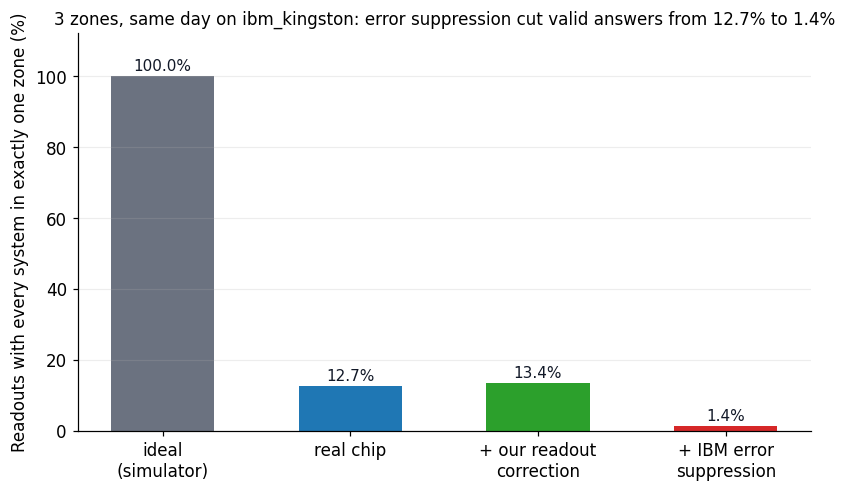

In [12]:
S17 = json.loads((ROOT / "results" / "17_hardware_3zone_suppression.json").read_text())
mean_valid = lambda variant, mode: 100 * np.mean([r[mode]["valid_share"] for r in S17["results"][variant]["rows"]])
labels = ["ideal\n(simulator)", "real chip", "+ our readout\ncorrection", "+ IBM error\nsuppression"]
vals = [100.0, mean_valid("plain", "raw"), mean_valid("plain", "readout_mitigated"), mean_valid("dd_twirl", "raw")]
assert vals[3] < vals[1] < vals[2]
fig, ax = plt.subplots(figsize=(7.6, 4.6))
bars = ax.bar(range(4), vals, color=[GRAY, BLUE, GREEN, RED], width=0.55)
for i, v in enumerate(vals):
    ax.text(i, v + 1.5, f"{v:.1f}%", ha="center", fontsize=10, color="#111827")
ax.set(xticks=range(4), xticklabels=labels, ylabel="Readouts with every system in exactly one zone (%)", ylim=(0, 112))
ax.yaxis.grid(True, alpha=0.22)
ax.set_title(f"3 zones, same day on {S17['backend']}: error suppression cut valid answers from {vals[1]:.1f}% to {vals[3]:.1f}%", fontsize=11)
plt.tight_layout()
plt.show()